# Pair 2: Product personalisation - DreamBooth-LoRA vs IP-Adapter

- **System A:** DreamBooth with LoRA on Stable Diffusion 1.5. I trained a small LoRA adapter for each product, so the word `sks` means "this product".
- **System B:** IP-Adapter.It takes one reference photo and needs no training per product.

Task is to making new lifestyle images of a specific product while keeping it recognisable.

In [10]:
import os, json, time, random, shutil
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
from PIL import Image
from diffusers import AutoencoderKL, DDPMScheduler, DPMSolverMultistepScheduler, StableDiffusionPipeline, UNet2DConditionModel
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from transformers import CLIPTextModel, CLIPTokenizer, CLIPModel, CLIPProcessor, ViTModel, ViTImageProcessor

device = "cuda"
sd = "stable-diffusion-v1-5/stable-diffusion-v1-5"
out = "results/pair2"
neg = "lowres, blurry, deformed, distorted, watermark, text"
products = {"teapot": "teapot", "backpack": "backpack", "colorful_sneaker": "sneaker", "bear_plushie": "stuffed animal"}
prompts = ["a {} on top of a wooden floor", "a {} on top of a white rug", "a {} with a city in the background",
           "a {} in the snow", "a {} on top of a mirror", "a red {}"]
seeds = [0, 1, 2, 3]
steps = 800   
lr = 1e-4
rank = 4
n_prior = 16
os.makedirs(out+"/images",exist_ok=True)
os.makedirs("results/summary",exist_ok=True)

In [2]:
def load_image(path,size=512):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    s = min(w,h)
    left = (w-s)//2
    top = (h-s)//2
    img = img.crop((left,top,left+s,top+s))
    img = img.resize((size,size))
    return img

def get_split(product):
    folder = "data/dreambooth/"+product
    paths = []
    for f in sorted(os.listdir(folder)):
        paths.append(folder+"/"+f)
    train = paths[:-1]
    held = paths[-1]   #last photo is only used for evaluation
    return train, held

## Train DreamBooth-LoRA (System A)
Skipped for a product if its adapter already exists.

In [3]:
def to_latent(img,vae):
    x = np.array(img).astype(np.float32)
    x = x/127.5-1
    x = torch.from_numpy(x).permute(2,0,1).unsqueeze(0)
    x = x.to(device,torch.float16)
    with torch.no_grad():
        z = vae.encode(x).latent_dist.sample()
    z = z*vae.config.scaling_factor
    return z

def embed(text,tok,te):
    ids = tok(text,padding="max_length",max_length=tok.model_max_length,truncation=True,return_tensors="pt").input_ids
    with torch.no_grad():
        e = te(ids.to(device))[0]
    return e

train_info = []
for product, cls in products.items():
    info_file = f"{out}/lora/{product}/train_info.json"
    if os.path.exists(info_file):
        with open(info_file) as f:
            train_info.append(json.load(f))
        continue

    random.seed(0)
    torch.manual_seed(0)
    start = time.time()
    tok = CLIPTokenizer.from_pretrained(sd,subfolder="tokenizer")
    te = CLIPTextModel.from_pretrained(sd,subfolder="text_encoder",torch_dtype=torch.float16).to(device)
    vae = AutoencoderKL.from_pretrained(sd,subfolder="vae",torch_dtype=torch.float16).to(device)
    unet = UNet2DConditionModel.from_pretrained(sd,subfolder="unet",torch_dtype=torch.float16).to(device)
    sched = DDPMScheduler.from_pretrained(sd,subfolder="scheduler")

    #prior images = normal class images made by the original model
    prior_dir = "data/prior/"+cls.replace(" ","_")
    os.makedirs(prior_dir,exist_ok=True)
    t = time.time()
    if len(os.listdir(prior_dir))<n_prior:
        solver = DPMSolverMultistepScheduler.from_pretrained(sd,subfolder="scheduler")
        p = StableDiffusionPipeline(vae=vae,text_encoder=te,tokenizer=tok,unet=unet,scheduler=solver,
                                    safety_checker=None,feature_extractor=None,requires_safety_checker=False)
        for i in range(n_prior):
            g = torch.Generator(device).manual_seed(1000+i)
            img = p("a photo of a "+cls,num_inference_steps=30,generator=g).images[0]
            img.save(f"{prior_dir}/{i:03d}.png")
        del p
    prior_time = time.time()-t

    train_files, held = get_split(product)
    inst = []
    for f in train_files:
        img = load_image(f)
        inst.append(to_latent(img,vae))
    prior = []
    for f in sorted(os.listdir(prior_dir))[:n_prior]:
        img = load_image(prior_dir+"/"+f)
        prior.append(to_latent(img,vae))
    e_inst = embed(f"a photo of sks {cls}",tok,te)
    e_prior = embed(f"a photo of a {cls}",tok,te)
    emb = torch.cat([e_inst,e_prior])
    del te, vae
    torch.cuda.empty_cache()

    #LoRA on the attention layers of the UNet
    unet.requires_grad_(False)
    config = LoraConfig(r=rank,lora_alpha=rank,init_lora_weights="gaussian",target_modules=["to_k","to_q","to_v","to_out.0"])
    unet.add_adapter(config)
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params:
        p.data = p.data.float()
    unet.enable_gradient_checkpointing()
    unet.train()
    opt = torch.optim.AdamW(params,lr=lr,weight_decay=1e-2)
    scaler = torch.amp.GradScaler("cuda")

    losses = []
    ckpt = {}
    torch.cuda.reset_peak_memory_stats()
    t = time.time()
    for step in range(1,steps+1):
        z = torch.cat([random.choice(inst),random.choice(prior)])   #one product image + one prior image
        noise = torch.randn_like(z)
        ts = torch.randint(0,1000,(2,),device=device)
        noisy = sched.add_noise(z,noise,ts)
        with torch.autocast("cuda",dtype=torch.float16):
            pred = unet(noisy,ts,emb).sample
        pred = pred.float()
        noise = noise.float()
        l_inst = F.mse_loss(pred[:1],noise[:1])
        l_prior = F.mse_loss(pred[1:],noise[1:])
        loss = l_inst+l_prior
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params,1.0)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad()
        losses.append([step, l_inst.item(), l_prior.item()])

        if step==400 or step==800:
            d = f"{out}/lora/{product}/step{step}"
            weights = get_peft_model_state_dict(unet)
            weights = convert_state_dict_to_diffusers(weights)
            StableDiffusionPipeline.save_lora_weights(d,unet_lora_layers=weights,safe_serialization=True)
            size = os.path.getsize(d+"/pytorch_lora_weights.safetensors")
            size = size/1024**2
            ckpt[step] = {"seconds": time.time()-t, "size_mb": size}

    train_time = time.time()-t
    n_params = 0
    for p in params:
        n_params += p.numel()
    memory = torch.cuda.max_memory_allocated()/1024**2
    losses = pd.DataFrame(losses,columns=["step","instance_loss","prior_loss"])
    losses.to_csv(f"{out}/lora/{product}/train_loss.csv",index=False)

    info = {"product": product, "train_images": len(train_files), "prior_image_time_s": prior_time,
            "train_time_s": train_time, "total_setup_time_s": time.time()-start, "train_memory_mb": memory,
            "lora_size_mb": ckpt[800]["size_mb"], "trainable_params": n_params, "checkpoints": ckpt}
    with open(info_file,"w") as f:
        json.dump(info,f,indent=2)
    train_info.append(info)
    print(product,"trained in",round(train_time),"s")
    del unet, opt
    torch.cuda.empty_cache()

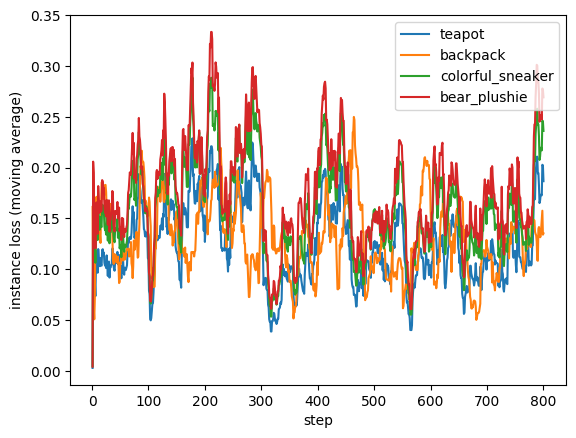

In [4]:
for product in products:
    l = pd.read_csv(f"{out}/lora/{product}/train_loss.csv")
    smooth = l.instance_loss.rolling(20,min_periods=1).mean()
    plt.plot(l.step,smooth,label=product)
plt.xlabel("step")
plt.ylabel("instance loss (moving average)")
plt.legend()
plt.savefig("results/summary/pair2_training_loss.png",dpi=200)
plt.show()

## Generation
Same SD 1.5 base, 30 DPM-Solver steps, guidance 7.5, seeds and negative prompt. Ablation: DreamBooth at 400 steps, IP-Adapter scale 0.4 and 0.8 (seeds 0, 1).

In [5]:
pipe = StableDiffusionPipeline.from_pretrained(sd,torch_dtype=torch.float16).to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe("a photo of a teapot",num_inference_steps=5)   #warm-up
log = []

def generate(model,setting,value,product,phrase,seed_list,extra={}):
    for i, prompt in enumerate(prompts):
        text = prompt.format(phrase)
        for seed in seed_list:
            g = torch.Generator(device).manual_seed(seed)
            torch.cuda.reset_peak_memory_stats()
            t = time.time()
            result = pipe(text,negative_prompt=neg,num_inference_steps=30,guidance_scale=7.5,generator=g,**extra)
            torch.cuda.synchronize()
            sec = time.time()-t
            memory = torch.cuda.max_memory_allocated()/1024**2
            file = f"{out}/images/{model}_{value}_{product}_p{i}_seed{seed}.png"
            result.images[0].save(file)
            flag = False
            if result.nsfw_content_detected:
                flag = result.nsfw_content_detected[0]
            eval_prompt = prompt.format(products[product])
            log.append([model, setting, value, product, i, eval_prompt, seed, sec, memory, flag, file])

for product, cls in products.items():
    for step in [800, 400]:
        setting = "main"
        seed_list = seeds
        if step==400:
            setting = "ablation"
            seed_list = [0, 1]
        pipe.load_lora_weights(f"{out}/lora/{product}/step{step}",weight_name="pytorch_lora_weights.safetensors")
        generate("dreambooth",setting,step,product,"sks "+cls,seed_list)
        pipe.unload_lora_weights()
    print("dreambooth done:",product)

pipe.load_ip_adapter("h94/IP-Adapter",subfolder="models",weight_name="ip-adapter_sd15.bin")
for product, cls in products.items():
    train_files, held = get_split(product)
    ref = load_image(train_files[0])
    for scale in [0.6, 0.4, 0.8]:
        setting = "main"
        seed_list = seeds
        if scale!=0.6:
            setting = "ablation"
            seed_list = [0, 1]
        pipe.set_ip_adapter_scale(scale)
        generate("ipadapter",setting,scale,product,cls,seed_list,{"ip_adapter_image": ref})
    print("ipadapter done:",product)
del pipe
torch.cuda.empty_cache()

log = pd.DataFrame(log,columns=["model","setting","value","product","prompt_id","eval_prompt","seed","seconds","memory_mb","safety_flag","file"])
log.to_csv(out+"/generation_log.csv",index=False)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

dreambooth done: teapot
dreambooth done: backpack
dreambooth done: colorful_sneaker
dreambooth done: bear_plushie
ipadapter done: teapot
ipadapter done: backpack


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ipadapter done: colorful_sneaker
ipadapter done: bear_plushie


## Metrics (from DreamBooth)
- DINO-I: DINO ViT-S/16 similarity between the generated image and the real photos (higher is better)
- CLIP-I: the same comparison with CLIP image features.
- CLIP-T: similarity between the image and the prompt written with the normal class name (higher is better)

In [6]:
clip = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").to(device)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")
dino = ViTModel.from_pretrained("facebook/dino-vits16",add_pooling_layer=False).to(device)
dino_proc = ViTImageProcessor.from_pretrained("facebook/dino-vits16")

def clip_image(img):
    inputs = clip_proc(images=img,return_tensors="pt").to(device)
    with torch.no_grad():
        e = clip.get_image_features(**inputs)[0]
    e = e/e.norm()
    return e

def clip_text(text):
    inputs = clip_proc(text=[text],return_tensors="pt",padding=True).to(device)
    with torch.no_grad():
        e = clip.get_text_features(**inputs)[0]
    e = e/e.norm()
    return e

def dino_image(img):
    inputs = dino_proc(images=img,return_tensors="pt").to(device)
    with torch.no_grad():
        e = dino(**inputs).last_hidden_state[0,0]   #CLS token
    e = e/e.norm()
    return e

real = {}
for product in products:
    train_files, held = get_split(product)
    held_img = load_image(held)
    all_dino = []
    for f in train_files+[held]:
        img = load_image(f)
        all_dino.append(dino_image(img))
    real[product] = {"dino": dino_image(held_img), "clip": clip_image(held_img), "dino_all": all_dino}

rows = []
for x in log.itertuples():
    img = Image.open(x.file).convert("RGB")
    d = dino_image(img)
    c = clip_image(img)
    r = real[x.product]
    sims = []
    for e in r["dino_all"]:
        sims.append((d@e).item())
    dino_held = (d@r["dino"]).item()
    clip_held = (c@r["clip"]).item()
    clip_t = (c@clip_text(x.eval_prompt)).item()
    rows.append([dino_held, np.mean(sims), clip_held, clip_t])

log[["dino_heldout","dino_all","clip_i_heldout","clip_t"]] = rows
log.to_csv(out+"/metrics.csv",index=False)

## Results
Bootstrap 95% confidence intervals over the 24 product × prompt combinations (averaged over seeds).

In [7]:
def bootstrap_ci(values,n=5000):
    rng = np.random.default_rng(0)
    means = []
    for i in range(n):
        sample = rng.choice(values,len(values))
        means.append(sample.mean())
    low, high = np.percentile(means,[2.5,97.5])
    return low, high

metrics = ["dino_heldout", "dino_all", "clip_i_heldout", "clip_t", "seconds", "memory_mb"]
log["unit"] = log["product"]+"_"+log.prompt_id.astype(str)

summary = []
for (model, value), part in log.groupby(["model","value"]):
    per_unit = part.groupby("unit")[metrics].mean()
    for m in metrics:
        low, high = bootstrap_ci(per_unit[m].values)
        summary.append([model, value, m, per_unit[m].mean(), low, high])
summary = pd.DataFrame(summary,columns=["model","value","metric","mean","ci_low","ci_high"])

main = log[log.setting=="main"]
a = main[main.model=="dreambooth"].groupby("unit")[metrics].mean()
b = main[main.model=="ipadapter"].groupby("unit")[metrics].mean()
paired = []
for m in metrics:
    diff = a[m]-b[m]
    low, high = bootstrap_ci(diff.values)
    paired.append([m, diff.mean(), low, high])
paired = pd.DataFrame(paired,columns=["metric","A_minus_B","ci_low","ci_high"])

costs = pd.DataFrame(train_info)
costs = costs[["product","prior_image_time_s","train_time_s","total_setup_time_s","train_memory_mb","lora_size_mb"]]

summary.to_csv("results/summary/pair2_summary.csv",index=False)
paired.to_csv("results/summary/pair2_paired.csv",index=False)
costs.to_csv("results/summary/pair2_setup_cost.csv",index=False)
print(summary[summary.metric.isin(["dino_heldout","clip_t"])].round(4))
print(paired.round(4))
print(costs.round(1))
print("safety flags:",log.safety_flag.sum())

         model  value        metric    mean  ci_low  ci_high
0   dreambooth  400.0  dino_heldout  0.5788  0.5415   0.6141
3   dreambooth  400.0        clip_t  0.2633  0.2501   0.2765
6   dreambooth  800.0  dino_heldout  0.6344  0.6081   0.6589
9   dreambooth  800.0        clip_t  0.2596  0.2460   0.2728
12   ipadapter    0.4  dino_heldout  0.5927  0.5587   0.6266
15   ipadapter    0.4        clip_t  0.2286  0.2154   0.2409
18   ipadapter    0.6  dino_heldout  0.6097  0.5804   0.6375
21   ipadapter    0.6        clip_t  0.2008  0.1842   0.2160
24   ipadapter    0.8  dino_heldout  0.5952  0.5663   0.6225
27   ipadapter    0.8        clip_t  0.1949  0.1787   0.2100
           metric  A_minus_B     ci_low    ci_high
0    dino_heldout     0.0247    -0.0110     0.0602
1        dino_all    -0.0027    -0.0312     0.0290
2  clip_i_heldout    -0.0301    -0.0525    -0.0073
3          clip_t     0.0588     0.0462     0.0710
4         seconds     0.1073     0.0804     0.1374
5       memory_mb -1247

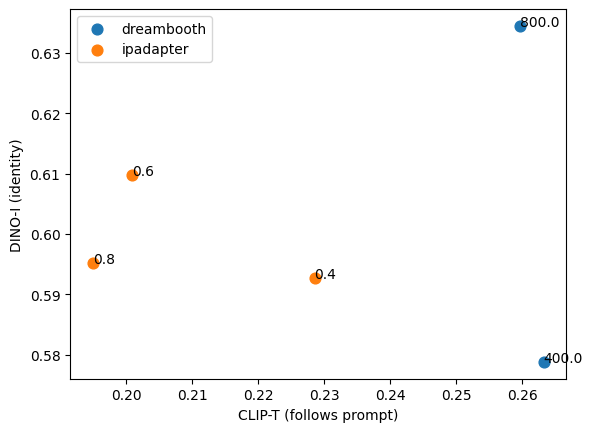

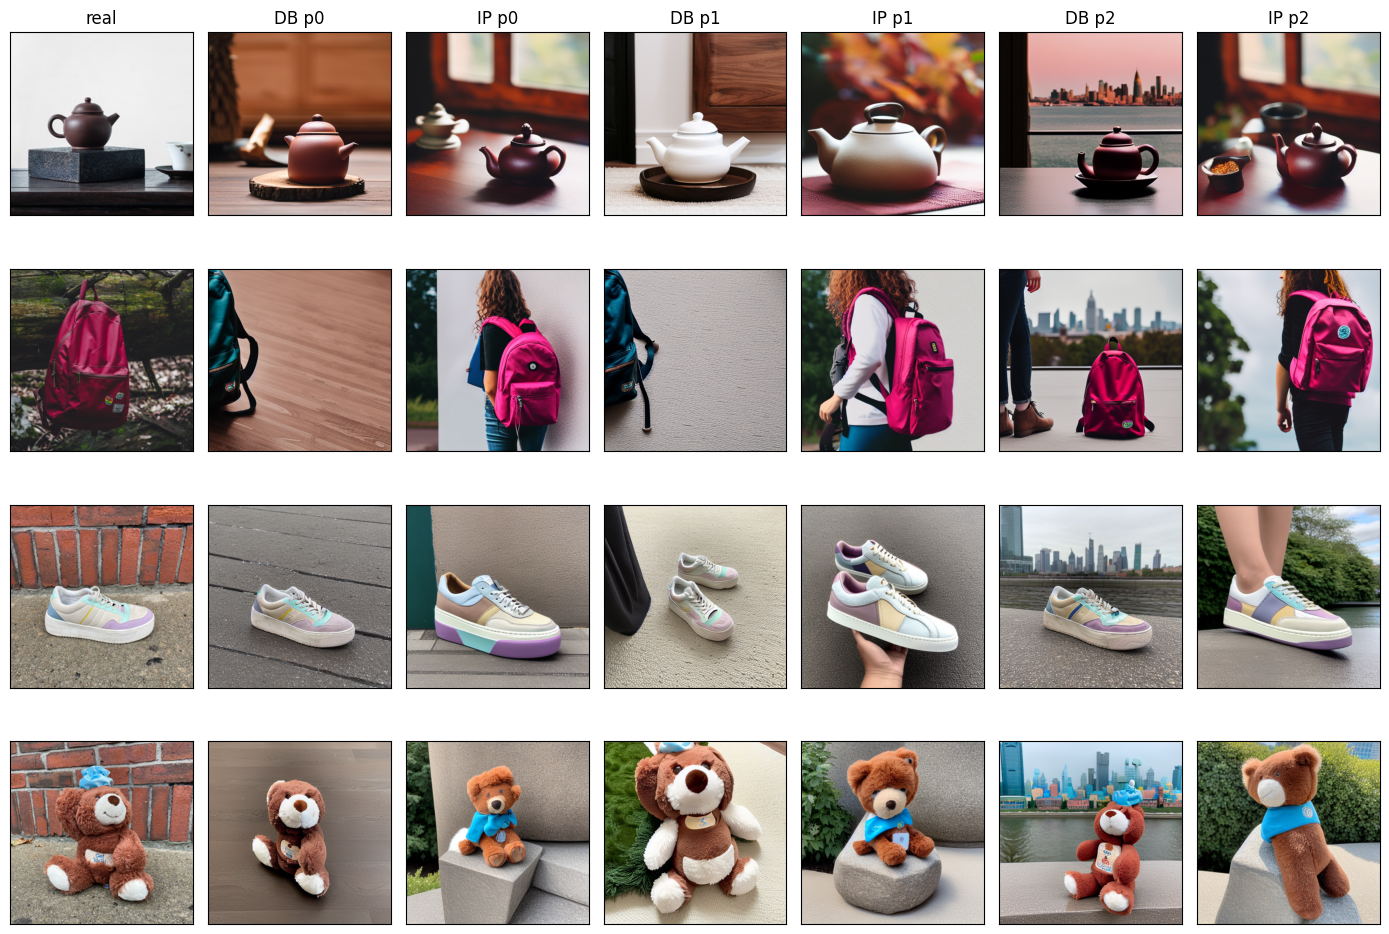

In [8]:
points = log.groupby(["model","value"])[["dino_heldout","clip_t"]].mean().reset_index()
for model in ["dreambooth", "ipadapter"]:
    p = points[points.model==model]
    plt.scatter(p.clip_t,p.dino_heldout,s=60,label=model)
    for r in p.itertuples():
        plt.annotate(str(r.value),(r.clip_t,r.dino_heldout))
plt.xlabel("CLIP-T (follows prompt)")
plt.ylabel("DINO-I (identity)")
plt.legend()
plt.savefig("results/summary/pair2_tradeoff.png",dpi=200)
plt.show()

fig, ax = plt.subplots(4,7,figsize=(14,10))
for i, product in enumerate(products):
    train_files, held = get_split(product)
    ax[i][0].imshow(load_image(held,256))
    for p in range(3):
        db = Image.open(f"{out}/images/dreambooth_800_{product}_p{p}_seed0.png")
        ip = Image.open(f"{out}/images/ipadapter_0.6_{product}_p{p}_seed0.png")
        ax[i][2*p+1].imshow(db)
        ax[i][2*p+2].imshow(ip)
titles = ["real", "DB p0", "IP p0", "DB p1", "IP p1", "DB p2", "IP p2"]
for j in range(7):
    ax[0][j].set_title(titles[j])
plt.setp(ax,xticks=[],yticks=[])
plt.tight_layout()
plt.savefig(out+"/examples.png",dpi=150)
plt.show()

## Blind rating sheet
I rate the images in `results/ratings/ratings_pair2.csv`.

In [9]:
os.makedirs("results/ratings/pair2_images",exist_ok=True)
for product in products:
    train_files, held = get_split(product)
    load_image(held).save(f"results/ratings/pair2_images/REAL_{product}.png")

rate = main[main.seed==0].sample(frac=1,random_state=1).reset_index(drop=True)
names = []
for i in range(len(rate)):
    names.append(f"img_{i:03d}.png")
rate["blind_name"] = names
for x in rate.itertuples():
    shutil.copy(x.file,"results/ratings/pair2_images/"+x.blind_name)
rate[["blind_name","model"]].to_csv("results/ratings/pair2_key_DO_NOT_OPEN.csv",index=False)

sheet = rate[["blind_name","eval_prompt"]].copy()
sheet["compare_with"] = "REAL_"+rate["product"]+".png"
for col in ["identity_1to5", "follows_prompt_1to5", "realistic_1to5", "usable_0or1"]:
    sheet[col] = ""
sheet.to_csv("results/ratings/ratings_pair2.csv",index=False)
print(len(sheet),"images to rate")

48 images to rate
